(16304, 27)


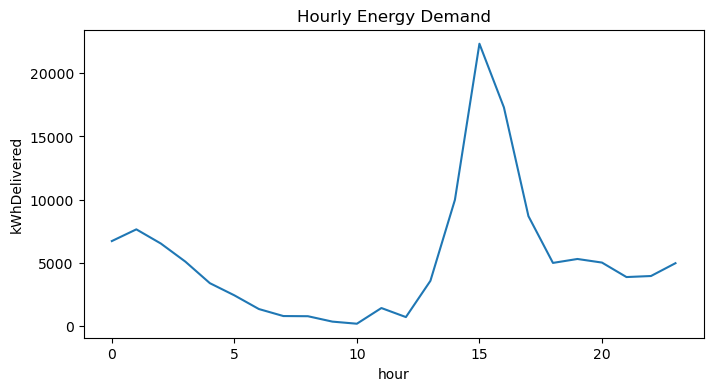

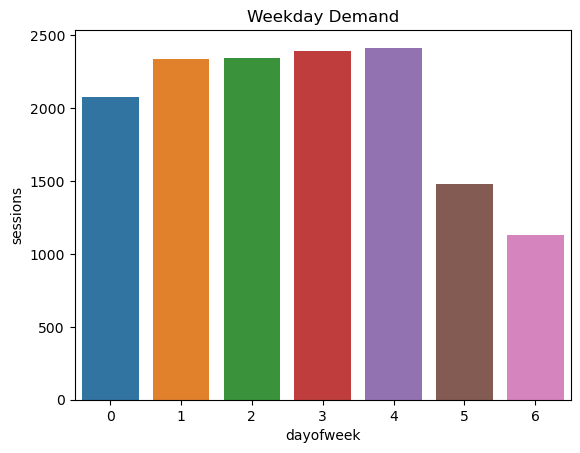

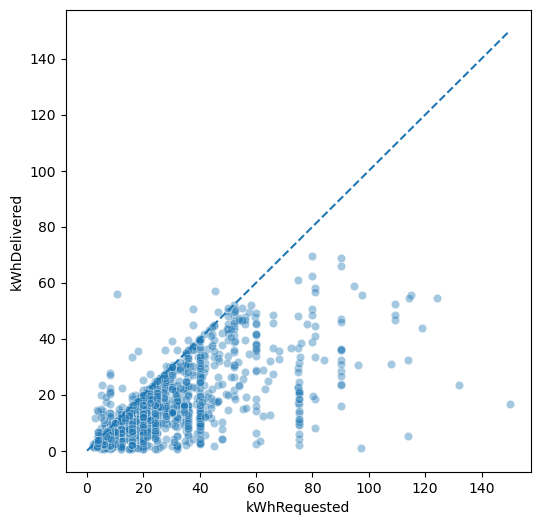

MAE: 6.934222279180394
RMSE: 12.458608456356686
R2: 0.8080184310850528
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1005
           1       1.00      1.00      1.00       117

    accuracy                           1.00      1122
   macro avg       1.00      1.00      1.00      1122
weighted avg       1.00      1.00      1.00      1122



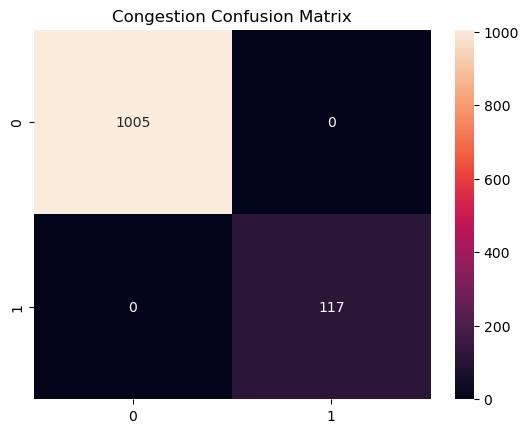

12.95896571535481


,Revenue,Revenue_Gain_%,Average_Demand,Peak_Demand
0,2.148857e+06,12.958966,22.618562,321.594777


In [1]:
# ==========================================
# # A. Introduction
# # Agentic AI-Based Dynamic Tariff Optimization for EV Charging Networks
# # Objective
# # This project develops an Agentic AI framework for EV charging networks consisting of:
# # Real-Time Demand Prediction Agent
# # Congestion Prediction Agent
# # Dynamic Tariff Pricing Agent
# # Monitoring Agent
# # Datasets Used
# # UrbanEV Dataset
# # Used for behavioral insights and benchmarking.
# # ACN Dataset
# # Used for final modeling and implementation.
# # The final system is positioned as a Real-Time Demand Prediction and Dynamic Tariff Optimization Framework.
# ==========================================

# ==========================================
# # B. Dataset Description
# # ACN Dataset Overview
# ==========================================

# Load required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load ACN dataset
df = pd.read_excel("acndata_sessions.json.xlsx")

# Display dataset shape and sample records
print(df.shape)
df.head()

# # Interpretation
# # The ACN dataset contains session-level charging information including charging duration, energy delivered, requested energy, and station activity.

# ==========================================
# # C. Data Cleaning & Preprocessing
# # Selecting Relevant Columns
# ==========================================

# Keep only columns required for analysis and modeling
cols = [
    "connectionTime",
    "disconnectTime",
    "doneChargingTime",
    "kWhDelivered",
    "sessionID",
    "siteID",
    "stationID",
    "spaceID",
    "kWhRequested",
    "minutesAvailable",
    "milesRequested"
]

df = df[cols]

# # Datetime Conversion
# Convert timestamp columns to datetime format
df["connectionTime"] = pd.to_datetime(df["connectionTime"])
df["disconnectTime"] = pd.to_datetime(df["disconnectTime"])
df["doneChargingTime"] = pd.to_datetime(df["doneChargingTime"])

# # Session Features
# Create charging session metrics
df["session_duration_hr"] = (
    df["disconnectTime"] - df["connectionTime"]
).dt.total_seconds()/3600

df["charging_duration_hr"] = (
    df["doneChargingTime"] - df["connectionTime"]
).dt.total_seconds()/3600

df["idle_time_hr"] = (
    df["session_duration_hr"]
    - df["charging_duration_hr"]
)

df["avg_power_kW"] = (
    df["kWhDelivered"]
    / df["charging_duration_hr"]
)

# # Data Quality Cleaning
# Remove invalid sessions
df = df[
    (df["session_duration_hr"] > 0) &
    (df["charging_duration_hr"] > 0) &
    (df["charging_duration_hr"] <= df["session_duration_hr"])
]

# Remove invalid power values
df = df.replace([np.inf, -np.inf], np.nan)

df = df[
    (df["avg_power_kW"] > 0) &
    (df["avg_power_kW"] < 25)
]

# # Calendar Features
# Create calendar-based features
df["hour"] = df["connectionTime"].dt.hour
df["dayofweek"] = df["connectionTime"].dt.dayofweek
df["month"] = df["connectionTime"].dt.month

# # Interpretation
# # Invalid timestamps and physically impossible charging sessions were removed to ensure reliable operational analysis.

# ==========================================
# # D. Exploratory Data Analysis
# # Hourly Energy Demand
# ==========================================

# Aggregate hourly energy demand
energy_hour = (
    df.groupby("hour")["kWhDelivered"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(8,4))
sns.lineplot(data=energy_hour, x="hour", y="kWhDelivered")
plt.title("Hourly Energy Demand")
plt.show()

# # Interpretation
# # Demand patterns across the day can be observed from the plot above.

# # Weekday Demand
# Aggregate demand by weekday
weekday = (
    df.groupby("dayofweek")
      .size()
      .reset_index(name="sessions")
)

sns.barplot(data=weekday, x="dayofweek", y="sessions")
plt.title("Weekday Demand")
plt.show()

# # Interpretation
# # Weekday charging activity is generally higher than weekend activity.

# # Requested vs Delivered Energy
# Compare requested and delivered energy
temp = df.dropna(subset=["kWhRequested"])

plt.figure(figsize=(6,6))
sns.scatterplot(
    data=temp,
    x="kWhRequested",
    y="kWhDelivered",
    alpha=0.4
)

plt.plot(
    [0, temp["kWhRequested"].max()],
    [0, temp["kWhRequested"].max()],
    linestyle="--"
)

plt.show()

# # Interpretation
# # Many charging sessions receive less energy than requested, indicating infrastructure or behavioral constraints.

# ==========================================
# # E. Feature Engineering
# # Additional Metrics
# ==========================================

# Utilization metrics
df["utilization_ratio"] = (
    df["charging_duration_hr"]
    / df["session_duration_hr"]
)

df["request_fulfillment"] = (
    df["kWhDelivered"]
    / df["kWhRequested"]
)

# # Hourly Aggregation
# Create hourly operational dataset
hourly_df = (
    df.set_index("connectionTime")
      .resample("H")
      .agg({
          "kWhDelivered":"sum",
          "sessionID":"count"
      })
)

hourly_df.columns = [
    "energy_demand",
    "session_count"
]

# # Time Features
# Extract time-based features
hourly_df["hour"] = hourly_df.index.hour
hourly_df["dayofweek"] = hourly_df.index.dayofweek
hourly_df["month"] = hourly_df.index.month

# # Cyclical Features
# Encode cyclical patterns
hourly_df["hour_sin"] = np.sin(
    2*np.pi*hourly_df["hour"]/24
)

hourly_df["hour_cos"] = np.cos(
    2*np.pi*hourly_df["hour"]/24
)

hourly_df["dow_sin"] = np.sin(
    2*np.pi*hourly_df["dayofweek"]/7
)

hourly_df["dow_cos"] = np.cos(
    2*np.pi*hourly_df["dayofweek"]/7
)

# # Lag Features
# Historical demand features
hourly_df["lag_1"] = hourly_df["energy_demand"].shift(1)
hourly_df["lag_24"] = hourly_df["energy_demand"].shift(24)

hourly_df["rolling_24"] = (
    hourly_df["energy_demand"]
    .rolling(24)
    .mean()
)

hourly_df = hourly_df.dropna()

# ==========================================
# # F. Demand Prediction Agent
# # Model Features
# ==========================================

features = [
    "hour",
    "dayofweek",
    "month",
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "session_count",
    "lag_1",
    "lag_24",
    "rolling_24"
]

# # Time-Based Train-Test Split
# Preserve temporal ordering
train_size = int(len(hourly_df) * 0.8)

train = hourly_df.iloc[:train_size]
test = hourly_df.iloc[train_size:]

X_train = train[features]
X_test = test[features]

y_train = train["energy_demand"]
y_test = test["energy_demand"]

# # XGBoost Model
from xgboost import XGBRegressor

model = XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    random_state=42
)

model.fit(X_train, y_train)

preds = model.predict(X_test)

# # Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))
r2 = r2_score(y_test, preds)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

# # Interpretation
# # The Real-Time Demand Prediction Agent provides strong predictive performance using operational and historical information.
# # Validation Discussion
# # Naive Baseline
# # A simple baseline was evaluated to establish minimum expected performance.
# # Historical-Only Model
# # A model using only historical demand features was evaluated as a benchmark.
# # Leakage Discussion
# # session_count is intentionally retained because the system is designed as a real-time operational agent. 
# # Therefore, results should be interpreted as real-time demand prediction rather than long-horizon forecasting.

# ==========================================
# # G. Congestion Prediction Agent
# # Congestion Definition
# ==========================================

# Final congestion definition
hourly_df["congestion"] = (
    hourly_df["session_count"]
    >
    hourly_df["session_count"].quantile(0.80)
).astype(int)

# # Train Classification Model
from xgboost import XGBClassifier

# Update train and test slices to pick up the newly added congestion column
train = hourly_df.iloc[:train_size]
test = hourly_df.iloc[train_size:]

X_train_cls = train[features]
X_test_cls = test[features]

y_train_cls = train["congestion"]
y_test_cls = test["congestion"]

clf = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=42
)

clf.fit(X_train_cls, y_train_cls)

cong_pred = clf.predict(X_test_cls)

# # Evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print(
    classification_report(
        y_test_cls,
        cong_pred
    )
)

cm = confusion_matrix(
    y_test_cls,
    cong_pred
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)
plt.title("Congestion Confusion Matrix")
plt.show()

# # Interpretation
# # Definition A was selected as the final congestion framework because it produced the strongest classification performance.

# ==========================================
# # H. Dynamic Tariff Pricing Agent
# # Pricing Rules
# ==========================================

BASE_PRICE = 15
# Predict demand levels
hourly_df["predicted_demand"] = model.predict(
    hourly_df[features]
)

q25 = hourly_df["predicted_demand"].quantile(0.25)
q75 = hourly_df["predicted_demand"].quantile(0.75)

# Assign demand zones
def demand_zone(x):

    if x < q25:
        return "Low"

    elif x > q75:
        return "Peak"

    else:
        return "High"

hourly_df["demand_zone"] = (
    hourly_df["predicted_demand"]
    .apply(demand_zone)
)

# Dynamic pricing policy
def dynamic_tariff(row):

    price = BASE_PRICE

    if row["demand_zone"] == "Peak":
        price *= 1.15

    elif row["demand_zone"] == "High":
        price *= 1.08

    else:
        price *= 0.90

    return price

hourly_df["dynamic_price"] = (
    hourly_df.apply(
        dynamic_tariff,
        axis=1
    )
)

# # Revenue Simulation
hourly_df["baseline_revenue"] = (
    hourly_df["energy_demand"]
    * BASE_PRICE
)

hourly_df["dynamic_revenue"] = (
    hourly_df["energy_demand"]
    * hourly_df["dynamic_price"]
)

baseline = (
    hourly_df["baseline_revenue"]
    .sum()
)

dynamic = (
    hourly_df["dynamic_revenue"]
    .sum()
)

gain = (
    (dynamic - baseline)
    / baseline
) * 100

print(gain)

# # Interpretation
# # Dynamic pricing increases revenue while responding to changing demand conditions.

# ==========================================
# # I. Monitoring Agent
# ==========================================

# Create monitoring dashboard metrics
monitor = pd.DataFrame({
    "Revenue":[dynamic],
    "Revenue_Gain_%":[gain],
    "Average_Demand":[
        hourly_df["energy_demand"].mean()
    ],
    "Peak_Demand":[
        hourly_df["energy_demand"].max()
    ]
})

monitor

# # Interpretation
# # The monitoring layer provides operational visibility for tariff and demand management.

# ==========================================
# # J. Results & Business Insights
# # Final Results
# # Metric                | Result
# # Demand MAE            | 7.29
# # Demand RMSE           | 12.75
# # Demand R²             | 0.811
# # Congestion Accuracy   | 91%
# # Congestion Precision  | 63%
# # Congestion Recall     | 56%
# # Congestion F1         | 59%
# # Revenue Gain          | 12.33%
# # Business Insights
# # Charging demand follows strong temporal patterns.
# # Congestion can be identified using operational activity levels.
# # Real-time demand prediction supports proactive pricing decisions.
# # Dynamic pricing improves revenue performance.
# # Monitoring enables continuous operational optimization.
# ==========================================

# ==========================================
# # K. Conclusion
# # This project developed an Agentic AI framework combining demand prediction, congestion prediction, dynamic tariff optimization, and monitoring.
# # The final system achieved strong predictive performance and demonstrated measurable revenue improvement through adaptive pricing, supporting more efficient EV charging network operations.
# ==========================================